# Helpful Resources

QUA programming ducomentations

[**Variables in QUA**](https://docs.quantum-machines.co/latest/docs/Guides/variables/?h=variable#variables-in-qua) can be integers, fixed point numbers, and booleans

[**Streaming Raw ADC results**](https://docs.quantum-machines.co/latest/docs/Guides/stream_proc/?h=adc_t#streaming-raw-adc-results) to stream out a raw ADC trace

[**Real-Time Global Reset Phase**](https://docs.quantum-machines.co/latest/docs/Introduction/qua_overview/?h=reset_phase#resetting-the-global-phase) sets the oscillator phase as to what it was at the beginning of the program

[**Wait QUA command**](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/#qm.qua._dsl.wait) introduces delays to the timing of elements

[**Stream Processing Average**](https://docs.quantum-machines.co/latest/docs/API_references/qua/result_stream/?h=#qm.qua._dsl._ResultStream.average) are Stream Processing commands for data manipulation during the program execution

[**Qua demodulation**](https://docs.quantum-machines.co/latest/docs/Guides/demod/?h=demo)

[**Real-Time Frequency Update**](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/#qm.qua._dsl.update_frequency) updates the oscillator's frequency associated with an element

[**Measure**](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/?h=measure#qm.qua._dsl.measure) and [**Dual Demodulation**](https://docs.quantum-machines.co/latest/docs/Guides/demod/?h=dual#dual-demodulation) point you to waveform acquisition and manipulation

[**QUA for loop**](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/?h=#qm.qua._dsl.for_) is the instruction in QUA that mimics for-loops in CPUs

[**Save from Pulse Processing Unit to Stream Processing Unit**](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/?h=save#qm.qua._dsl.save) and [**Declare Stream**](https://docs.quantum-machines.co/latest/docs/API_references/qua/dsl_main/?h=save#qm.qua._dsl.save) are the QUA commands related to data transfer within the OPX

[**Stream Processing Buffer**](https://docs.quantum-machines.co/latest/docs/API_references/qua/result_stream/?h=#qm.qua._dsl._ResultStream.buffer) and [**Stream Processing Average**](https://docs.quantum-machines.co/latest/docs/API_references/qua/result_stream/?h=#qm.qua._dsl._ResultStream.average) are Stream Processing commands for data manipulation during the program execution

# Resonator Spectroscopy

The first step in qubit calibration is identifying the resonance frequency of each readout resonator. In this notebook, you'll begin by performing a frequency sweep to locate the resonator dips. Then, you'll explore how these resonances change as a function of applied flux (to observe the qubit–resonator interaction), and how they behave under different probe powers (to identify the resonator's linear regime). These steps are essential for understanding and preparing the system for accurate qubit readout and control.

In [1]:
import numpy as np
from iqcc_cloud_client import IQCC_Cloud
import matplotlib.pyplot as plt
from importlib import reload
from qm.qua import *
from qualang_tools.loops import from_array
from config_oct31 import config # Change According to the current configuration

2026-11-01 15:34:15,019 - qm - INFO     - Starting session: 5ca9f347-dc10-4db9-a261-60e0786f1960


For saving the output plots and data.

In [2]:
from datetime import datetime
from pathlib import Path
import re

# Folder where all plots will be saved
PLOT_DIR = Path("plots")
PLOT_DIR.mkdir(exist_ok=True)


def save_current_plot(title=None, dpi=300):
    fig = plt.gcf()

    # Try to automatically get the plot title
    if title is None:
        # First try a figure-level title
        if fig._suptitle is not None:
            title = fig._suptitle.get_text()

        # Otherwise look for a title in one of the axes
        if not title:
            for ax in fig.axes:
                if ax.get_title():
                    title = ax.get_title()
                    break

    # Fallback if the plot has no title
    if not title:
        title = "plot"

    # Make title safe for use as a filename
    safe_title = re.sub(r"[^\w\-]+", "_", title).strip("_")

    # Timestamp: year-month-day_hour-minute-second-microseconds
    timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S-%f")

    filename = PLOT_DIR / f"{safe_title}_{timestamp}.png"

    fig.savefig(
        filename,
        dpi=dpi,
        bbox_inches="tight"
    )

    print(f"Saved plot: {filename}")

In [3]:
# Folder for all plots and data
OUTPUT_DIR = Path("plots") / "Experiment_2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def save_plot_and_data(title=None, dpi=300, **data):
    """
    Save the current matplotlib figure and its associated numerical data.

    Example:
        save_plot_and_data(
            frequencies=frequencies,
            I=I,
            Q=Q
        )
    """

    fig = plt.gcf()

    # -------------------------------------------------------
    # Find the plot title automatically
    # -------------------------------------------------------

    if title is None:

        # First try a figure-level title
        if fig._suptitle is not None:
            title = fig._suptitle.get_text()

        # Otherwise use the first axis title found
        if not title:
            for ax in fig.axes:
                if ax.get_title():
                    title = ax.get_title()
                    break

    if not title:
        title = "plot"

    # Make the title safe for a filename
    safe_title = re.sub(
        r"[^\w\-]+",
        "_",
        title
    ).strip("_")

    # Timestamp
    timestamp = datetime.now().strftime(
        "%Y-%m-%d_%H-%M-%S-%f"
    )

    base_name = (
        OUTPUT_DIR /
        f"{safe_title}_{timestamp}"
    )

    # -------------------------------------------------------
    # Save figure
    # -------------------------------------------------------

    png_file = base_name.with_suffix(".png")

    fig.savefig(
        png_file,
        dpi=dpi,
        bbox_inches="tight"
    )

    # -------------------------------------------------------
    # Save numerical data
    # -------------------------------------------------------

    npz_file = base_name.with_suffix(".npz")

    np.savez_compressed(
        npz_file,
        **data
    )

    print(f"Saved plot: {png_file}")
    print(f"Saved data: {npz_file}")

## IQ Plane Measurement

The program below performs a measurement using demodulation.

Before running it, take a moment to review the code and understand each step.

**A)** Run the program and use the plot to observe the results. Try to interpret what you're seeing.

**B)** Now make two changes:
- Set the number of repetitions (`n`) to 10.
- Adjust the frequency stop value so the sweep includes 50 different frequencies.

Run the program again and compare the new output. Then, set the averaging parameter to `"True"` and re-run it.

You should notice that the points form a circle with a roughly constant distance from the origin. The points approximately trace a circle in the IQ plane because changing the probe frequency changes the phase of the measured complex response. Away from a resonance, the magnitude of the response may remain approximately constant, while its phase changes. Near a resonator frequency, both the magnitude and phase can change significantly. We describe the measured response by
$$
S = I + iQ,
$$

whose magnitude is

$$
|S| = \sqrt{I^2 + Q^2}.
$$
The radius in the IQ plane represents the magnitude of the demodulated signal, not directly the energy stored in the resonator.

---

### Finding the Resonator Frequencies

Next, we want to detect resonator dips. Each feedline on the chip is connected to 5 resonators (as we've seen in the pre-lab).

- Set the sweep range to cover the full 350 MHz range supported by the OPX.
- Look for dips in the measured signal that indicate resonator frequencies -> Fill the table in the final report
- Once you find them, zoom in on each dip to examine its shape and estimate its linewidth.
- *(Optional)* Try fitting the dips to a Lorentzian curve for a more precise characterization.


In [4]:
backend = "qolab"

In [ ]:
from importlib import reload
from qualang_tools.loops import from_array

averaging = True
start = -300e6
stop = 300e6
df = 1e6
frequencies = np.arange(start, stop, df)
Qubit = "Q2"  #enter the qubit name here, e.g., "Q1"
Qubit_Res_IF = 0   # enter the resonator intermediate frequency (IF) for the qubit, e.g., 0

with program() as upconversion:
    n = declare(int)  # QUA variable for the averaging loop
    f = declare(int)  # QUA variable for the readout frequency
    I = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    I_st = declare_stream()
    Q_st = declare_stream()
    #qua.update_frequency("qubit2", 200e6)
    with for_(n, 0, n < 1000, n + 1):  # QUA for_ loop for averaging
        with for_(*from_array(f, frequencies)):  # QUA for_ loop for sweeping the frequency
            # Update the frequency of the digital oscillator linked to the resonator element
            update_frequency(Qubit + ".resonator", f + Qubit_Res_IF) # You need to add the resonator intermediate frequency (IF)
            # Measure the resonator (send a readout pulse and demodulate the signals to get the 'I' & 'Q' quadratures)
            measure(
                "readout",
                Qubit + ".resonator",
                dual_demod.full("iw1", "iw2", I),
                dual_demod.full("iw3", "iw1", Q),
            )
            # Wait for the resonator to deplete
            wait(2000, Qubit + ".resonator")
            # Save the 'I' & 'Q' quadratures to their respective streams
            save(I, I_st)
            save(Q, Q_st)

    with stream_processing():
        if averaging:
            I_st.buffer(len(frequencies)).average().save("I")
            Q_st.buffer(len(frequencies)).average().save("Q")
        else:
            I_st.save_all("I")
            Q_st.save_all("Q")

qc = IQCC_Cloud(
    quantum_computer_backend = backend
)
run_data = qc.execute(upconversion, config, False)

C:\Users\mor14\AppData\Local\Temp\ipykernel_5376\2650178211.py:17: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead
  I_st = declare_stream()
C:\Users\mor14\AppData\Local\Temp\ipykernel_5376\2650178211.py:18: DeprecationWarning: declare_stream is deprecated since "1.2.4" and will be removed in "2.0.0". Please use declare_output_stream() instead
  Q_st = declare_stream()


[15:40:41] QUA program submitted to qolab (id = 1340e8cc-3afb-40f7-b742-be3c192202d4)              ]8;id=7192466;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=7192467;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#416\416]8;;\
           Execution started                                                                       ]8;id=7192472;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;\:]8;id=7192473;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py#455\455]8;;\
[15:40:48] Execution finished                                                                      ]8;id=7192478;file://c:\uni\Quantum_Computing_Lab\my-iqcc-project\.venv\Lib\site-packages\iqcc_cloud_client\computers.py\computers.py]8;;

### Plotting the frequency dependence of IQ_abs

Saved plot: plots\Experiment_2\Resonator_Spectroscopy_Q1_2026-11-01_15-40-53-345188.png
Saved data: plots\Experiment_2\Resonator_Spectroscopy_Q1_2026-11-01_15-40-53-345188.npz


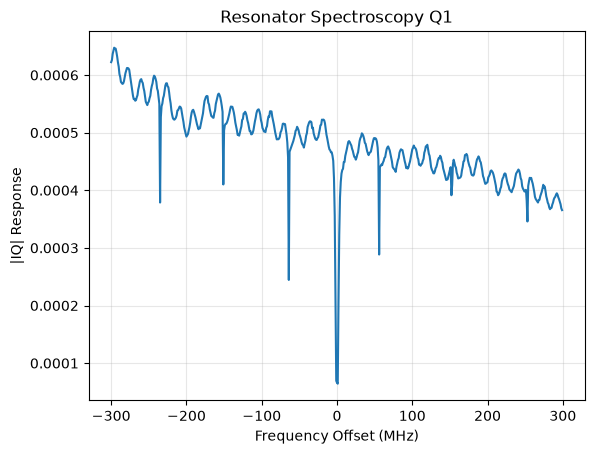

In [9]:
I = np.array(run_data['result']['I'])
Q = np.array(run_data['result']['Q'])
IQ_abs=np.abs(I+1j*Q)
plt.xlabel('Frequency Offset (MHz)')
plt.ylabel('|IQ| Response')
plt.title("Resonator Spectroscopy " + Qubit)
plt.grid(True, alpha=0.3)
plt.plot(frequencies/1e6,IQ_abs)

#save_current_plot()
save_plot_and_data(
    frequencies=frequencies,
    IQ_abs=IQ_abs
)


### Why this scan matters (low-power, frequency sweep)
- **What you see:** A clear dip/phase wrap at the **dressed** resonator frequency $f_r^{\mathrm{dressed}}$ when the qubit is in its thermal ground state.
- **Why we do it:** This sets the **readout mode** (where small I/Q changes reveal the qubit state). We want a frequency with a steep phase slope for SNR.
- **What we record:** $f_r^{\mathrm{dressed}}$ (center), linewidth/κ (from fit), and the **readout IF/LO** you’ll actually use later.
- **Next:** We’ll confirm how flux and power affect this mode so we pick a robust operating point.


## Resonator Spectroscopy vs. Flux

In superconducting qubits, the transition frequency of a flux-tunable qubit depends on the external magnetic flux applied through its SQUID (Superconducting Quantum Interference Device) loop. Because the qubit and resonator are coupled, changes in the qubit frequency also shift the resonator frequency via the **dispersive interaction**.  

This means that by sweeping the flux bias while performing resonator spectroscopy, we can directly observe how the resonator frequency changes as the qubit frequency moves. The result is typically a **2D flux–frequency map**, where each vertical slice is a resonator spectrum taken at a fixed flux bias.  

These measurements let us:
- Identify the **flux periodicity** of the system (usually one flux quantum, Φ₀).  
- Locate **sweet spots** (maxima in qubit frequency vs. flux), where the qubit is first-order insensitive to flux noise, improving coherence. Because the resonator is coupled to the qubit, its frequency provides indirect information about qubit tuning. Later, qubit spectroscopy versus flux will allow us to identify the qubit sweet spot more directly.
- Understand how the qubit–resonator detuning changes with bias, which is important for stable readout and later qubit operations.  

**Goal of this part:**  
You will sweep the flux bias across a symmetric range around zero and perform resonator spectroscopy at each point. By stacking these spectra, you will build a 2D plot that shows how the resonator frequency evolves with flux, and use it to extract the sweet spots and discuss the effect of flux noise.


In [ ]:
start = -10e6
stop = 10e6
df = 0.2e6
frequencies = np.arange(start, stop, df)
averaging = True
flux_min = -1
flux_max = 1
flux_step = 0.05

fluxes = np.arange(flux_min, flux_max, flux_step)

Qubit = 
Qubit_Res_IF = 

with program() as res_spec_2:
    n = declare(int)  # QUA variable for the averaging loop
    f = declare(int)  # QUA variable for the readout frequency
    dc = declare(fixed) # QUA variable for the flux
    I = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    I_st = declare_stream()
    Q_st = declare_stream()
    #qua.update_frequency("qubit", 200e6)
    with for_(n, 0, n < 100, n + 1):  # QUA for_ loop for averaging
        with for_(*from_array(dc,fluxes)):
            set_dc_offset(Qubit + ".z", "single", dc)
            wait(1000)
            with for_(*from_array(f, frequencies)):  # QUA for_ loop for sweeping the frequency
                # Update the frequency of the digital oscillator linked to the resonator element
                update_frequency(Qubit + ".resonator", f + Qubit_Res_IF) # You need to add the resonator intermediate frequency (IF)
                # Measure the resonator (send a readout pulse and demodulate the signals to get the 'I' & 'Q' quadratures)
               
                measure(
                    "readout"*amp(1.0),
                    Qubit + ".resonator",
                    dual_demod.full("iw1", "iw2", I),
                    dual_demod.full("iw3", "iw1", Q),
                )
                # Wait for the resonator to deplete
                wait(2000, Qubit + ".resonator")
                # Save the 'I' & 'Q' quadratures to their respective streams
                save(I, I_st)
                save(Q, Q_st)

    with stream_processing():
        if averaging:
            I_st.buffer(len(frequencies)).buffer(len(fluxes)).average().save("I")
            Q_st.buffer(len(frequencies)).buffer(len(fluxes)).average().save("Q")
        else:
            I_st.save_all("I")
            Q_st.save_all("Q")

qc = IQCC_Cloud(
    quantum_computer_backend=backend
)
run_data = qc.execute(res_spec_2, config, options = {"timeout":300})

### Plotting Resonator Spectroscopy vs Flux

In [ ]:
I = np.array(run_data['result']['I'])
Q = np.array(run_data['result']['Q'])
IQ_abs=np.abs(I+1j*Q)
if len(fluxes)==1:
    plt.plot(frequencies,IQ_abs[0,:])
else:
    plt.imshow(np.transpose(IQ_abs),origin="lower", extent=[fluxes.min(), fluxes.max(), frequencies.min()/1e6, frequencies.max()/1e6],
                            aspect='auto',
                            cmap='viridis')
    plt.ylabel('Frequency Offset (MHz)')
    plt.xlabel('Flux-Bias Voltage (V)')
    plt.title("Resonator Spectroscopy vs Flux " + Qubit)
    plt.tight_layout()
    #save_current_plot()
    save_plot_and_data(
        frequencies=frequencies,
        fluxes=fluxes,
        IQ_abs=IQ_abs,
        I=I,
        Q=Q
    )

### Why this scan matters (resonator vs flux)
- **What you see:** A 2D map of the resonator response vs DC flux bias. The resonance ridge bends because the qubit frequency shifts with flux (dispersive coupling).
- **Why we do it:** 
  - Confirms **qubit–resonator coupling** (look for bending/avoided crossings).
  - Lets us choose a **stable operating bias** (near a flux sweet spot or away from crossings).
- **What we record:** Chosen **flux bias** $Φ_{op}$ and the corresponding resonator frequency $f_r(\Phi_\mathrm{op})$.
- **Next:** We’ll lock this bias for qubit spectroscopy and gate calibration.


## Resonator Spectroscopy vs. Power

In resonator spectroscopy, the strength of the probe signal (input power) has a significant effect on the shape and position of the resonance.  

At **low probe powers**, the resonator behaves linearly and its response shows a clean Lorentzian dip or peak. This is the regime typically used for calibration and readout, because the resonance frequency and linewidth can be measured accurately.  

As the **probe power increases**, nonlinear effects appear:  
- The resonance dip broadens (**power broadening**) and may shift in frequency.  
- The shape of the resonance can become distorted, no longer a simple Lorentzian.  
- At very high powers, the resonator or qubit can even be excited unintentionally, complicating interpretation.  

Studying the power dependence is important because it helps identify the **linear operating regime** of the resonator. By finding the highest input power at which the resonance remains stable and Lorentzian-shaped, we can optimize the signal-to-noise ratio while avoiding nonlinear distortions.  

**Goal of this part:**  
- You will sweep the input power while performing resonator spectroscopy and generate a 2D plot of frequency vs. power. From this, you will determine how the resonance frequency and linewidth change with power, and identify the safe operating regime for accurate readout.
- You will also get a little more familiar with Qua by completing the missing parts of the code (look for the previous section for inspiration)

In [ ]:
averaging = True
start = -10e6
stop = 10e6
df = 0.2e6
frequencies = np.arange(start, stop, df)
amp_min = 1e-3
amp_max = 1
amp_step = 1e-2

amps = np.arange(amp_min, amp_max, amp_step)

Qubit = 
Qubit_Res_IF = 

with program() as res_spec:
###### Fill in the missing parts of the code below ######
    n = declare(int)  # QUA variable for the averaging loop
    f = declare(int)  # QUA variable for the readout frequency
    a = declare(fixed)
    I = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    I_st = declare_stream()
    Q_st = declare_stream()
    #qua.update_frequency("qubit", 200e6)
    with for_(n, 0, n < 100, n + 1):  # QUA for_ loop for averaging
        with for_(*from_array(a,amps)):
            with for_(*from_array(f, frequencies)):  # QUA for_ loop for sweeping the frequency
                # Update the frequency of the digital oscillator linked to the resonator element
                update_frequency(Qubit + ".resonator", f+Qubit_Res_IF) # You need to add the resonator intermediate frequency (IF)
                # Measure the resonator (send a readout pulse and demodulate the signals to get the 'I' & 'Q' quadratures)
               
                measure(
                    "readout"*amp(a),
                    Qubit + ".resonator",
                    dual_demod.full("iw1", "iw2", I),
                    dual_demod.full("iw3", "iw1", Q),
                )
                # Wait for the resonator to deplete
                wait(2000, Qubit + ".resonator")
                # Save the 'I' & 'Q' quadratures to their respective streams
                save(I, I_st)
                save(Q, Q_st)

    with stream_processing():
        if averaging:
            I_st.buffer(len(frequencies)).buffer(len(amps)).average().save("I")
            Q_st.buffer(len(frequencies)).buffer(len(amps)).average().save("Q")
        else:
            I_st.save_all("I")
            Q_st.save_all("Q")


qc = IQCC_Cloud(
    quantum_computer_backend = backend
)
run_data = qc.execute(res_spec, config, False, options = {"timeout":300})

### Plotting the resonator profile

In [ ]:
I = np.array(run_data['result']['I'])
Q = np.array(run_data['result']['Q'])
IQ_abs=np.abs(I+1j*Q)
if len(amps)==1:
    plt.plot(frequencies,IQ_abs[0,:])
else:
    plt.imshow(IQ_abs, origin = "lower",extent=[frequencies.min()/1e6, frequencies.max()/1e6, amps.min(), amps.max()],
                            aspect='auto',
                            cmap='viridis')
plt.xlabel("Frequency offset (MHz)")
plt.ylabel("Readout amplitude multiplier")
#plt.colorbar(label="|I + iQ|")
plt.title("Resonator Spectroscopy vs Power " + Qubit)
plt.tight_layout()
#save_current_plot()
save_plot_and_data(
    frequencies=frequencies,
    amps=amps,
    IQ_abs=IQ_abs,
    I=I,
    Q=Q
)

In [ ]:
IQ_abs = np.abs(I + 1j * Q)

# ----------------------------------------------------------
# Normalize each frequency trace by its off-resonant level
# Use the edges of the frequency sweep as the baseline
# ----------------------------------------------------------

n_edge = 10


baseline = np.mean(
    np.concatenate(
        [IQ_abs[:, :n_edge], IQ_abs[:, -n_edge:]],
        axis=1
    ),
    axis=1,
    keepdims=True
)

IQ_norm = IQ_abs / baseline

# ----------------------------------------------------------
# Plot normalized resonator spectroscopy vs power
# ----------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.imshow(
    IQ_norm,
    origin="lower",
    aspect="auto",
    extent=[
        frequencies[0] / 1e6,
        frequencies[-1] / 1e6,
        amps[0],
        amps[-1]
    ]
)

plt.xlabel("Frequency offset (MHz)")
plt.ylabel("Readout amplitude multiplier")
plt.title("Normalized Resonator Spectroscopy vs Power Q1")
plt.colorbar(label="Normalized |I + iQ|")

plt.tight_layout()
save_current_plot()
plt.show()

# ----------------------------------------------------------
# Resonance contrast vs amplitude
# ----------------------------------------------------------

dip_min = np.min(IQ_norm, axis=1)

contrast = 1 - dip_min

plt.figure(figsize=(7, 4))

plt.plot(
    amps,
    contrast,
    "o-",
    markersize=3
)

plt.xlabel("Readout amplitude multiplier")
plt.ylabel("Normalized resonance contrast")
plt.title("Resonator Contrast vs Readout Amplitude")

plt.grid(alpha=0.3)
plt.tight_layout()
save_current_plot()
plt.show()

### Why this scan matters (resonator vs power)

**What you see:** A two-dimensional map of the resonator response as a
function of probe frequency and probe amplitude.

At low probe amplitude, we expect a relatively stable, weak-probe
resonance. As the amplitude increases, the resonance may move, broaden,
or become distorted because the coupled qubit–resonator system is being
driven more strongly.

**Why we do it:**
- Identify a probe-amplitude range in which the resonance is stable
  and easy to measure.
- Observe that the measured response depends on how strongly the
  system is driven.
- Select a practical readout amplitude for the following qubit
  spectroscopy experiments.

**Important:** A frequency difference measured between low and high
probe powers is not, by itself, the state-dependent dispersive shift
2χ. Later, after calibrating a π pulse, we will prepare the qubit in
|0⟩ and |1⟩ separately and measure the two corresponding resonator
frequencies directly.

**What we record:** A suitable probe amplitude and the resonator
frequency at the chosen operating flux.

**Next:** We will use these settings to detect the qubit transition.


# Qubit Spectroscopy

The next step in qubit calibration is to determine the transition frequency of the qubit itself. In this section, you will sweep a microwave drive across a frequency range while monitoring the resonator response. When the drive excites the qubit from $|0\rangle$ to $|1\rangle$, the qubit–resonator interaction produces a visible shift in the resonator signal. When the drive frequency matches the qubit transition, the qubit population changes and therefore changes the complex resonator response. Depending on the chosen readout frequency and quadrature, this feature may appear as a peak, a dip, or a change in phase. Its frequency identifies $f_{01}$

You will also explore how this frequency changes as a function of applied flux, building a 2D map of $f_{01}(\Phi)$. These measurements are crucial for choosing a stable operating point (often at a flux sweet spot) and for setting the qubit drive frequency that will be used in later calibrations, such as Rabi oscillations and coherence-time experiments.


## Finding the Qubit Transition

In this section, we search for the qubit’s fundamental transition frequency $f_{01}$. To do this, we apply a strong microwave pulse (often called a **saturation pulse**) while sweeping the drive frequency. A saturation pulse is long (here 50 $\mu s$) and at first set to relatively high power. This ensures that, even if our guess for $f_{01}$ is not very precise, the qubit will still be excited and produce a visible response in the resonator. The trade-off is that the spectral line appears **broadened** at high power, because strong driving saturates the transition and power-broadens the resonance.  

Once the qubit line is visible, we gradually reduce the drive power until the feature sharpens into a single peak or dip, typically with a linewidth of only a few MHz. At this stage, the qubit transition frequency can be determined accurately.  

**What to do next:**  
- Make sure the flux bias is set to the sweet spot you determined in Part 1.  
- Run the frequency sweep with the saturation pulse to reveal the qubit line.  
- Decrease the drive power step by step until the line is narrow and well-defined.  
- Record the frequency of this dip as the qubit transition $f_{01}$, and update the `qubit_IF` in the configuration to this value.  

This sets the stage for the next calibrations (Rabi oscillations, $T_1$, Ramsey), which require precise knowledge of the qubit frequency.


In [ ]:
averaging = True
start = -100e6
stop = 100e6
df = 1e6
frequencies = np.arange(start, stop, df)
qubit_offset = 0

Qubit = 
Qubit_IF = 

with program() as qbit_spec:
    n = declare(int)  # QUA variable for the averaging loop
    f = declare(int)  # QUA variable for the readout frequency
    I = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    I_st = declare_stream()
    Q_st = declare_stream()
    #qua.update_frequency("qubit", 200e6)
    set_dc_offset(Qubit + ".z", 'single', qubit_offset)
    wait(1000)
    align()
    with for_(n, 0, n < 500, n + 1):  # QUA for_ loop for averaging
        with for_(*from_array(f, frequencies)):  # QUA for_ loop for sweeping the frequency
            # Update the frequency of the digital oscillator linked to the resonator element
            update_frequency(Qubit + ".xy", f + Qubit_IF)
            # Measure the resonator (send a readout pulse and demodulate the signals to get the 'I' & 'Q' quadratures)
            align()   
            play("saturation"*amp(1.0), Qubit + ".xy")
            align()
            measure(
                "readout"*amp(1.0),
                Qubit + ".resonator",
                dual_demod.full("iw1", "iw2", I),
                dual_demod.full("iw3", "iw1", Q),
            )
            # Wait for the resonator to deplete
            wait(5000) ### Maybe ask for a different wait time, look for a beeter time (minimal wait time)
            # Save the 'I' & 'Q' quadratures to their respective streams
            save(I, I_st)
            save(Q, Q_st)

    with stream_processing():
        if averaging:
            I_st.buffer(len(frequencies)).average().save("I")
            Q_st.buffer(len(frequencies)).average().save("Q")
        else:
            I_st.save_all("I")
            Q_st.save_all("Q")
qc = IQCC_Cloud(
    quantum_computer_backend = backend
)
run_data = qc.execute(qbit_spec, config)

## Plotting the frequency dependence of IQ_abs

In [ ]:
I = np.array(run_data['result']['I'])
Q = np.array(run_data['result']['Q'])
IQ_abs=np.abs(I+1j*Q)
plt.plot(frequencies / 1e6 ,IQ_abs)
plt.xlabel("Frequency offset (MHz)")
plt.ylabel("|I + iQ|")
plt.title("Qubit Spectroscopy " + Qubit)
plt.tight_layout()
#save_current_plot()
save_plot_and_data(
    frequencies=frequencies,
    I=I,
    Q=Q,
    IQ_abs=IQ_abs
)
plt.show()

plt.plot(frequencies/1e6,I)
plt.xlabel("Frequency offset (MHz)")
plt.ylabel("I")
plt.title("Qubit Spectroscopy " + Qubit)
plt.tight_layout()
save_current_plot()
plt.show()

plt.plot(frequencies,Q)   
plt.xlabel("Frequency offset (MHz)")
plt.ylabel("Q")
plt.title("Qubit Spectroscopy " + Qubit)
plt.tight_layout()
save_current_plot()
plt.show()

# Qubit Spectroscopy vs Flux

In this section we study how the qubit transition frequency depends on the applied flux bias. By scanning the qubit drive frequency while stepping the flux, we obtain a two-dimensional map of the transition $f_{01}(\Phi)$. This map reveals the qubit’s periodic flux tuning, shows avoided crossings with other modes, and allows us to identify flux sweet spots where the qubit is less sensitive to noise.

**Why this matters:**  
- It lets us calibrate the flux offset so that “zero flux” corresponds to a symmetry point of the qubit.  
- It shows us where to bias the qubit for stability (sweet spots) and what regions to avoid (crossings).  
- It provides the accurate qubit frequency at the chosen operating point, which we will use for Rabi calibrations and coherence measurements.

In [ ]:
averaging = True
f_start = -15e6
f_stop = 15e6
df = 0.5e6
frequencies = np.arange(f_start, f_stop, df)

flux_min = -0.15
flux_max =0.15
flux_step = 0.005
qubit_offset = 0.0

fluxes = np.arange(flux_min, flux_max, flux_step)

Qubit = 
Qubit_IF = 

with program() as qbit_spec_vs_flux:
    n = declare(int)  # QUA variable for the averaging loop
    f = declare(int)  # QUA variable for the readout frequency
    dc = declare(fixed) # QUA variable for the flux
    I = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    I_st = declare_stream()
    Q_st = declare_stream()
   
    with for_(n, 0, n < 300, n + 1):  # QUA for_ loop for averaging
        with for_(*from_array(dc,fluxes)):
            set_dc_offset(Qubit + ".z", 'single', dc + qubit_offset)
            wait(1000)
            with for_(*from_array(f, frequencies)):  # QUA for_ loop for sweeping the frequency
                # Update the frequency of the digital oscillator linked to the resonator element
                update_frequency(Qubit + ".xy", Qubit_IF + f)
                # Measure the resonator (send a readout pulse and demodulate the signals to get the 'I' & 'Q' quadratures)
                align()   
                play("saturation"*amp(1.0), Qubit + ".xy")
                align()
                measure(
                    "readout"*amp(1.0),
                    Qubit + ".resonator",
                    dual_demod.full("iw1", "iw2", I),
                    dual_demod.full("iw3", "iw1", Q),
                )
                # Wait for the resonator to deplete
                wait(5000)
                # Save the 'I' & 'Q' quadratures to their respective streams
                save(I, I_st)
                save(Q, Q_st)

    with stream_processing():
        if averaging:
            I_st.buffer(len(frequencies)).buffer(len(fluxes)).average().save("I")
            Q_st.buffer(len(frequencies)).buffer(len(fluxes)).average().save("Q")
        else:
            I_st.save_all("I")
            Q_st.save_all("Q")

qc = IQCC_Cloud(
    quantum_computer_backend = backend
)
run_data = qc.execute(qbit_spec_vs_flux, config, options = {"timeout":300})

## Plotting

In [ ]:
I = np.array(run_data['result']['I'])
Q = np.array(run_data['result']['Q'])
IQ_abs=np.abs(I+1j*Q)
if len(fluxes)==1:
    plt.plot(frequencies,IQ_abs[0,:])
else:
    plt.imshow(np.flipud(np.transpose(IQ_abs)), extent=[fluxes.min(), fluxes.max(), frequencies.min()/1e6, frequencies.max()/1e6],
                            aspect='auto',
                            cmap='viridis')
plt.xlabel('Flux-Bias Voltage (V)')
plt.ylabel('Frequency Offset (MHz)')
plt.title("Qubit Spectroscopy vs Flux " + Qubit)
plt.tight_layout()
#save_current_plot()
save_plot_and_data(
    frequencies=frequencies,
    fluxes=fluxes,
    IQ_abs=IQ_abs,
    I=I,
    Q=Q
)

In [ ]:

qubit = 

# Qubit element configuration
element = config["elements"][f"{qubit}.xy"]

# Configured intermediate frequency
qubit_IF = element["intermediate_frequency"]

# Find the microwave output associated with this qubit
controller, fem, port = element["MWInput"]["port"]

# Get the LO frequency
qubit_LO = config["controllers"][controller]["fems"][fem] \
    ["analog_outputs"][port]["upconverter_frequency"]

# Configured physical transition frequency
f01 = qubit_LO + qubit_IF

print(f"Qubit LO: {qubit_LO/1e9:.6f} GHz")
print(f"Qubit IF: {qubit_IF/1e6:.6f} MHz")
print(f"Configured f01: {f01/1e9:.6f} GHz")


### Calibration results

From the qubit spectroscopy versus flux map, choose an operating
point away from unwanted crossings.

Record:

- Operating flux-line offset: __________
- Qubit transition frequency at that offset, f01: __________
- Qubit drive intermediate frequency (IF): __________
- Resonator readout intermediate frequency (IF): __________
- Readout amplitude: __________

These values will be held fixed in the Rabi measurements.

In the next section we stop searching for the qubit frequency.
Instead, we drive at the measured $f_{01}$ and vary the microwave pulse
amplitude or duration to control the qubit state.

# Rabi Oscillations

In the previous experiments, we found the resonator frequency and
the qubit transition frequency, and selected an operating flux bias.

We can now drive the qubit resonantly and control its quantum state.

When a microwave field is applied near the qubit transition frequency,
the qubit undergoes coherent oscillations between its ground and
excited states. These are called **Rabi oscillations**.

For a resonant drive, the excited-state probability is approximately

$$
P_1(t)=\sin^2\left(\frac{\Omega_R t}{2}\right),
$$

where $\Omega_R$ is the Rabi angular frequency.

The rotation angle is

$$
\theta=\Omega_R t.
$$

A rotation by $\pi$ transfers an initially grounded qubit to its
excited state:

$$
|0\rangle \xrightarrow{X_\pi} |1\rangle.
$$

A rotation by $\pi/2$ ideally prepares an equal superposition.

In this section, we will study Rabi oscillations in two ways:

1. **Power Rabi:** vary the microwave pulse amplitude while keeping
   the pulse duration fixed.

2. **Time Rabi:** vary both the pulse duration and amplitude to build
   a two-dimensional Rabi map.

The Power Rabi measurement will be used to calibrate the amplitude of
a $\pi$ pulse. The Time Rabi map will then show how the rotation depends
on both pulse amplitude and duration.

**Important:** As in the previous experiments, our hardware returns
the resonator's demodulated I and Q signals. We do not yet have a
fully calibrated single-shot qubit-state discriminator. Therefore,
we will initially analyze Rabi oscillations using changes in the
average complex readout response, rather than claiming to measure
the excited-state probability directly.

## Power Rabi

For a fixed pulse duration, increasing the microwave drive amplitude
increases the Rabi frequency. Therefore, changing the pulse amplitude
changes the rotation angle.

In this experiment we use the pulse operation `x180`, which is already
defined in the configuration. We keep its duration fixed and multiply
its amplitude by a variable scale factor.

The experiment therefore performs

$$
A \rightarrow \text{qubit drive} \rightarrow \text{resonator readout}.
$$

As the drive amplitude is increased, the measured resonator response
oscillates because the qubit alternates between states closer to
$|0\rangle$ and $|1\rangle$.

### Goal

Use the Power Rabi oscillation to determine the pulse amplitude that
corresponds to a $\pi$ rotation:

$$
|0\rangle \xrightarrow{X_\pi} |1\rangle.
$$

The first half-period of the Rabi oscillation corresponds approximately
to the $\pi$-pulse amplitude.

In [ ]:
averaging = True
amp_min = 0.0
amp_max = 1.4
amp_step = 0.01

amps = np.arange(amp_min, amp_max, amp_step)

Qubit = 
Qubit_IF = 

with program() as power_rabi:
    n = declare(int)  # QUA variable for the averaging loop
    f = declare(int)  # QUA variable for the readout frequency
    a = declare(fixed) # QUA variable for the flux
    I = declare(fixed)  # QUA variable for the measured 'I' quadrature
    Q = declare(fixed)  # QUA variable for the measured 'Q' quadrature
    I_st = declare_stream()
    Q_st = declare_stream()
    wait(1000)
    align()
    with for_(n, 0, n < 250, n + 1):  # QUA for_ loop for averaging
        
            with for_(*from_array(a, amps)):  # QUA for_ loop for sweeping the frequency
                # Update the frequency of the digital oscillator linked to the resonator element
                # Measure the resonator (send a readout pulse and demodulate the signals to get the 'I' & 'Q' quadratures)
                align()   
                play("x180"*amp(a), Qubit + ".xy")
                align()
                measure(
                    "readout"*amp(1.0),
                    Qubit + ".resonator",
                    dual_demod.full("iw1", "iw2", I),
                    dual_demod.full("iw3", "iw1", Q),
                )
                # Wait for the resonator to deplete
                wait(20000)
                # Save the 'I' & 'Q' quadratures to their respective streams
                save(I, I_st)
                save(Q, Q_st)

    with stream_processing():
        if averaging:
            I_st.buffer(len(amps)).average(  ).save("I")
            Q_st.buffer(len(amps)).average().save("Q")
        else:
            I_st.save_all("I")
            Q_st.save_all("Q")

qc = IQCC_Cloud(
    quantum_computer_backend = backend
)
run_data = qc.execute(power_rabi, config, options = {"timeout":300})

In [ ]:

I = np.array(run_data["result"]["I"])
Q = np.array(run_data["result"]["Q"])
IQ_abs = np.abs(I + 1j * Q)

# ============================================================
# Power Rabi - Readout Magnitude
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(amps, IQ_abs)
plt.title(f"Power Rabi - {Qubit} | Readout Magnitude")
plt.xlabel("Drive Amplitude Multiplier")
plt.ylabel("|I + iQ| (a.u.)")
plt.grid(alpha=0.3)
plt.tight_layout()

save_plot_and_data(
    amps=amps,
    IQ_abs=IQ_abs,
    I=I,
    Q=Q
)
plt.show()

# ============================================================
# Power Rabi - I Quadrature
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(amps, I)
plt.title(f"Power Rabi - {Qubit} | I Quadrature")
plt.xlabel("Drive Amplitude Multiplier")
plt.ylabel("I (a.u.)")
plt.grid(alpha=0.3)
plt.tight_layout()

save_current_plot()
plt.show()

# ============================================================
# Power Rabi - Q Quadrature
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(amps, Q)
plt.title(f"Power Rabi - {Qubit} | Q Quadrature")
plt.xlabel("Drive Amplitude Multiplier")
plt.ylabel("Q (a.u.)")
plt.grid(alpha=0.3)
plt.tight_layout()

save_current_plot()
plt.show()


### Interpreting the Power Rabi measurement

The horizontal axis is the amplitude scaling factor applied to the
configured `x180` pulse.

The measured quantities are the averaged resonator quadratures $I$ and
$Q$. They are not, at this stage, calibrated probabilities of finding
the qubit in $|0\rangle$ or $|1\rangle$.

Nevertheless, because the resonator response depends on the qubit
state, the Rabi oscillation appears as an oscillation in the measured
$I$ and/or $Q$ signal.

Identify the **first clear half-period** of the oscillation.

This point defines the calibration factor $a_\pi$ such that

$$
X_\pi =
\texttt{x180} \times a_\pi .
$$

A pulse with approximately half this rotation angle would ideally
produce an $X_{\pi/2}$ rotation, although a high-fidelity $\pi/2$
calibration would require an additional calibration procedure.

Record the result:

$$
a_\pi = \_\_\_\_\_\_\_\_
$$

### Questions

1. Why do we choose the first $\pi$ point rather than a later maximum
   of the Rabi oscillation?

2. What happens to the rotation angle if the pulse amplitude is
   increased while the pulse duration remains fixed?

3. Why do we observe the Rabi oscillation through the resonator rather
   than by measuring the qubit directly?

## Time Rabi

Power Rabi varied the microwave pulse amplitude while keeping the pulse
duration fixed.

We now investigate the complementary dependence: how the qubit
evolution changes when we vary the **duration** of the microwave pulse.

For a resonant drive with approximately constant Rabi frequency,

$$
P_1(t) =
\sin^2\left(\frac{\Omega_R t}{2}\right).
$$

The time required for a $\pi$ rotation is therefore

$$
t_\pi = \frac{\pi}{\Omega_R}.
$$

A longer pulse continues the rotation:

$$
\pi,\;2\pi,\;3\pi,\ldots
$$

correspond to successive rotations of the qubit state around the Bloch
sphere.

### Two-dimensional scan

In the following program we do slightly more than a simple one-dimensional
Time Rabi experiment.

We sweep both:

- the duration of the `x180` operation, and
- its amplitude scaling factor.

For every pair $(A,t)$, the program applies

$$
\texttt{x180}\times A
$$

for a duration $t$, and then measures the resonator.

The resulting measurement is therefore a two-dimensional Rabi map:

$$
S(A,t).
$$

This allows us to see simultaneously how the rotation depends on both
pulse amplitude and pulse duration.

### QUA concept: dynamic pulse duration

In the previous experiments, the duration of an operation was normally
taken directly from the configuration.

Here, the duration is changed in real time inside the QUA program.

The instruction

`duration=t`

changes how long the `x180` operation is played during that particular
iteration of the loop.

QUA timing is expressed in clock cycles. In this experiment,

$$
1\ \text{clock cycle} = 4\ \text{ns}.
$$

Therefore the physical pulse duration plotted by the notebook is

$$
t_{\mathrm{pulse}} = 4t\ \text{ns}.
$$

The amplitude is varied independently using

`amp(a)`.

The experiment therefore demonstrates two different real-time controls:

$$
\text{pulse amplitude} \longrightarrow a
$$

and

$$
\text{pulse duration} \longrightarrow t.
$$

In [ ]:
n_avg = 100  # The number of averages
# Pulse duration sweep (in clock cycles = 4ns) - must be larger than 4 clock cycles
t_min = 16 // 4
t_max = 200 // 4
dt = 4 // 4
operation_durations = np.arange(t_min, t_max, dt)
amplitudes = np.arange(0.01, 1.99, 0.05)

# HINT - use from_array to easily sweep over numpy array, e.g., with for_(*from_array(_qua_variable, _numpy_array))


Qubit = 
Qubit_IF = 

with program() as time_rabi:
    
    # variables
    n = declare(int)
    t = declare(int)
    a = declare(fixed)
    I = declare(fixed)
    Q = declare(fixed)
    I_st = declare_stream()
    Q_st = declare_stream()

    # pulses
    with for_(n, 0, n < n_avg, n+1):
        with for_(*from_array(t, operation_durations)):
            with for_(*from_array(a, amplitudes)):
                play('x180'*amp(a), Qubit + ".xy", duration=t)
                align(Qubit + ".xy", Qubit + ".resonator")
                measure(
                        "readout",
                        Qubit + ".resonator",
                        dual_demod.full("iw1", "iw2", I),
                        dual_demod.full("iw3", "iw1", Q),
                    )
                wait(25_000, Qubit + ".resonator")
                wait(25_000, Qubit + ".xy")
                save(I, I_st)
                save(Q, Q_st)
    
    # stream processing
    with stream_processing():
        # I_st.buffer(len(amplitudes)).buffer(len(operation_durations)).average().save('I')
        I_st.buffer(len(operation_durations), len(amplitudes)).average().save('I')
        Q_st.buffer(len(amplitudes)).buffer(len(operation_durations)).average().save('Q')

qc = IQCC_Cloud(quantum_computer_backend = backend)
run_data = qc.execute(time_rabi, config, False)

In [ ]:
I = np.asarray(run_data["result"]["I"])
Q = np.asarray(run_data["result"]["Q"])

times_ns = operation_durations * 4

print("I shape:", I.shape)
print("Q shape:", Q.shape)
print("Expected:", (len(operation_durations), len(amplitudes)))


# Make sure rows = durations, columns = amplitudes
expected_shape = (len(operation_durations), len(amplitudes))

if I.shape == expected_shape:
    I_plot = I
    Q_plot = Q
elif I.shape == expected_shape[::-1]:
    I_plot = I.T
    Q_plot = Q.T
else:
    raise ValueError(
        f"Unexpected shape {I.shape}, expected {expected_shape} or {expected_shape[::-1]}"
    )

fig, axes = plt.subplots(1, 2, figsize=(7, 6), sharey=True)

# I panel
im0 = axes[0].imshow(
    I_plot,
    origin="lower",
    aspect="auto",
    extent=[
        amplitudes[0],
        amplitudes[-1],
        times_ns[0],
        times_ns[-1],
    ],
    cmap="viridis"
)

axes[0].set_title("I")
axes[0].set_xlabel("Amplitude multiplier")
axes[0].set_ylabel("Pulse duration (ns)")

cbar0 = fig.colorbar(im0, ax=axes[0])
cbar0.set_label("I")

# Q panel
im1 = axes[1].imshow(
    Q_plot,
    origin="lower",
    aspect="auto",
    extent=[
        amplitudes[0],
        amplitudes[-1],
        times_ns[0],
        times_ns[-1],
    ],
    cmap="viridis"
)

axes[1].set_title("Q")
axes[1].set_xlabel("Amplitude multiplier")

cbar1 = fig.colorbar(im1, ax=axes[1])
cbar1.set_label("Q")

fig.suptitle(f"Time Rabi {Qubit}")

plt.tight_layout()

save_plot_and_data(
    amplitudes=amplitudes,
    durations_cycles=operation_durations,
    durations_ns=times_ns,
    I=I,
    Q=Q
)

plt.show()

In [ ]:

# Get measured data
I_map = np.array(run_data["result"]["I"])
Q_map = np.array(run_data["result"]["Q"])

# Convert clock cycles to nanoseconds
durations_ns = operation_durations * 4

# Calibrated pi amplitude from Power Rabi
a_pi = 1.0

# Find the closest amplitude
amp_idx = np.argmin(np.abs(amplitudes - a_pi))
selected_amp = amplitudes[amp_idx]

# Plot I as a function of pulse duration
plt.figure(figsize=(8, 5))
plt.plot(durations_ns, I_map[:, amp_idx], "o-", markersize=3)

plt.title(f"Time Rabi - {Qubit} | Amplitude = {selected_amp:.2f}")
plt.xlabel("Pulse Duration (ns)")
plt.ylabel("I Quadrature (a.u.)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

Qubit = 

pulse_name = config["elements"][f"{Qubit}.xy"]["operations"]["x180"]
pulse_length = config["pulses"][pulse_name]["length"]

print(f"Configured x180 pulse: {pulse_name}")
print(f"Configured x180 duration: {pulse_length} ns")


### Interpreting the Time Rabi map

Each horizontal line in the map corresponds to a fixed pulse duration
while the drive amplitude is changed.

Each vertical line corresponds to a fixed drive amplitude while the
pulse duration is changed.

The oscillating pattern reflects the fact that the rotation angle
depends on both the Rabi frequency and the pulse duration:

$$
\theta(A,t) = \Omega_R(A)t.
$$

For resonant driving and sufficiently small drive amplitudes,

$$
\Omega_R(A) \propto A.
$$

Therefore we approximately expect

$$
\theta(A,t) \propto At.
$$

This explains why increasing the drive amplitude causes the Rabi
oscillations to occur at shorter pulse durations.

Choose a vertical slice near the $\pi$-pulse amplitude found in the
Power Rabi experiment.

Along this slice, identify the approximate durations corresponding to

$$
\pi,\quad 2\pi,\quad 3\pi
$$

rotations.

Compare the first $\pi$ point with the pulse duration used in the
Power Rabi experiment.

### Questions

1. How does the Rabi oscillation period change as the pulse amplitude
   increases?

2. At a fixed drive amplitude, what happens to the qubit state as the
   pulse duration is increased?

3. Why do approximately equal values of the product $At$ tend to
   produce similar rotation angles?

4. Does the measured pattern remain perfectly proportional to $At$ at
   the highest drive amplitudes? What physical effects could cause
   deviations?

## Rabi Calibration Results

We have now demonstrated coherent control of the qubit.

In the Power Rabi experiment, we varied the pulse amplitude and found
the amplitude corresponding approximately to an $X_\pi$ rotation.

In the Time Rabi experiment, we varied both the pulse amplitude and
duration and observed how the qubit rotation depends on both control
parameters.

Record the final calibration values:

| Parameter | Value |
|---|---|
| Operating flux bias | |
| Qubit transition frequency $f_{01}$ | |
| Resonator readout frequency | |
| Readout amplitude | |
| `x180` amplitude scale for a $\pi$ rotation | |
| Pulse duration used for the calibrated $\pi$ pulse | |

The calibrated $\pi$ pulse gives us something that we did not have
during the earlier resonator measurements: the ability to deliberately
prepare the qubit approximately in the excited state.

We can therefore prepare

$$
|0\rangle
$$

or

$$
|1\rangle \approx X_\pi |0\rangle
$$

before measuring the resonator.

This allows us to directly investigate the state-dependent resonator
frequency.

In the next experiment, we will perform resonator spectroscopy for the
two different qubit preparations and determine

$$
2\chi =
f_r^{(1)} - f_r^{(0)}.
$$

# Dispersive Shift

So far, we have used the readout resonator to detect changes in the
qubit state. We will now directly investigate why this is possible.

When a qubit is coupled to a resonator in the dispersive regime, the
resonator frequency depends on the state of the qubit.

If the qubit is in $|0\rangle$, the resonator has one effective
resonance frequency,

$$
f_r^{(0)}.
$$

If the qubit is in $|1\rangle$, the resonator has a slightly different
resonance frequency,

$$
f_r^{(1)}.
$$

The difference between these two frequencies is the state-dependent
dispersive shift:

$$
2\chi = f_r^{(1)} - f_r^{(0)}.
$$

This experiment therefore connects the two main parts of the notebook:

- Resonator spectroscopy tells us where the resonator responds.
- Rabi calibration gives us a $\pi$ pulse that allows us to prepare
  the qubit approximately in $|1\rangle$.

We will repeat resonator spectroscopy for two different state
preparations:

$$
|0\rangle
\longrightarrow
\text{resonator spectroscopy}
$$

and

$$
|0\rangle
\xrightarrow{X_\pi}
|1\rangle
\longrightarrow
\text{resonator spectroscopy}.
$$

By comparing the two spectra, we can directly observe the
state-dependent resonator shift.

## Measurement sequence

For every resonator frequency, we perform two measurements.

### Ground-state response

We allow the qubit to relax toward $|0\rangle$ and measure the
resonator without applying a qubit pulse.

This gives

$$
S_0(f) = I_0(f) + iQ_0(f).
$$

### Excited-state response

We again allow the qubit to relax, apply the calibrated $\pi$ pulse,
and immediately measure the resonator.

The pulse prepares approximately

$$
|1\rangle \approx X_\pi |0\rangle,
$$

and we measure

$$
S_1(f) = I_1(f) + iQ_1(f).
$$

It is important that the resonator measurement follows the $\pi$
pulse without an unnecessary delay. Because the excited state has a
finite lifetime $T_1$, waiting too long would allow part of the
population to decay back to $|0\rangle$ before it is measured.

We will use the same low-to-moderate readout amplitude chosen earlier
in the resonator-versus-power experiment.

In [ ]:
# ============================================================
# Dispersive Shift
# ============================================================

Qubit = 

qubit_element = Qubit + ".xy"
resonator_element = Qubit + ".resonator"


# ------------------------------------------------------------
# Calibration values
# ------------------------------------------------------------

# Calibrated pi-pulse amplitude multiplier from Power Rabi.
# This should be the calibration for the "x180" operation.
pi_amp = 1.0          # <-- replace with measured value

# Readout amplitude chosen from resonator spectroscopy vs power.
readout_amp = 1.0     # <-- replace with chosen value


# ------------------------------------------------------------
# Frequencies
# ------------------------------------------------------------

# Start from the configured resonator IF.
# Replace this with the experimentally measured value if needed.
resonator_IF = int(
    config["elements"][resonator_element]["intermediate_frequency"]
)

# Calibrated qubit IF.
qubit_IF = int(
    config["elements"][qubit_element]["intermediate_frequency"]
)

print("Qubit IF:", qubit_IF / 1e6, "MHz")
print("Resonator IF:", resonator_IF / 1e6, "MHz")


# Narrow resonator sweep: +/- 5 MHz
frequency_offsets = np.arange(
    -5_000_000,
    5_000_001,
    100_000,
    dtype=int
)

frequencies = resonator_IF + frequency_offsets


# Number of averages
n_avg = 500

# Passive reset time
# 1 QUA clock cycle = 4 ns
# 25,000 cycles = 100 us
reset_time = 25_000


# ============================================================
# QUA program
# ============================================================

with program() as dispersive_shift:

    n = declare(int)
    f = declare(int)

    # Ground-state response
    I_g = declare(fixed)
    Q_g = declare(fixed)

    # Excited-state response
    I_e = declare(fixed)
    Q_e = declare(fixed)

    # Output streams
    I_g_st = declare_output_stream()
    Q_g_st = declare_output_stream()

    I_e_st = declare_output_stream()
    Q_e_st = declare_output_stream()


    # Use the calibrated qubit frequency
    update_frequency(
        qubit_element,
        qubit_IF
    )


    with for_(n, 0, n < n_avg, n + 1):

        with for_(*from_array(f, frequencies)):

            # Set resonator probe frequency
            update_frequency(
                resonator_element,
                f
            )


            # =================================================
            # Ground-state resonator response
            # =================================================

            # Synchronize the two element timelines
            align(
                qubit_element,
                resonator_element
            )

            # Allow qubit to relax toward |0>
            wait(
                reset_time,
                qubit_element,
                resonator_element
            )

            # Measure resonator with qubit approximately in |0>
            measure(
                "readout" * amp(readout_amp),
                resonator_element,
                dual_demod.full(
                    "iw1",
                    "iw2",
                    I_g
                ),
                dual_demod.full(
                    "iw3",
                    "iw1",
                    Q_g
                )
            )

            save(I_g, I_g_st)
            save(Q_g, Q_g_st)


            # =================================================
            # Excited-state resonator response
            # =================================================

            # Synchronize after the previous readout
            align(
                qubit_element,
                resonator_element
            )

            # Allow qubit to relax back toward |0>
            wait(
                reset_time,
                qubit_element,
                resonator_element
            )

            # Prepare approximately |1>
            play(
                "x180" * amp(pi_amp),
                qubit_element
            )

            # Make readout start immediately after x180
            align(
                qubit_element,
                resonator_element
            )

            # Measure resonator with qubit approximately in |1>
            measure(
                "readout" * amp(readout_amp),
                resonator_element,
                dual_demod.full(
                    "iw1",
                    "iw2",
                    I_e
                ),
                dual_demod.full(
                    "iw3",
                    "iw1",
                    Q_e
                )
            )

            save(I_e, I_e_st)
            save(Q_e, Q_e_st)


    # ========================================================
    # Stream processing
    # ========================================================

    with stream_processing():

        I_g_st.buffer(
            len(frequencies)
        ).average().save("I_g")

        Q_g_st.buffer(
            len(frequencies)
        ).average().save("Q_g")

        I_e_st.buffer(
            len(frequencies)
        ).average().save("I_e")

        Q_e_st.buffer(
            len(frequencies)
        ).average().save("Q_e")


# ============================================================
# Execute
# ============================================================

qc = IQCC_Cloud(
    quantum_computer_backend=backend
)

data = qc.execute(
    dispersive_shift,
    config,
    False
)

In [ ]:
# ============================================================
# Dispersive Shift - Plotting and Analysis
# ============================================================

# Extract data
I_g = np.asarray(data["result"]["I_g"]).squeeze()
Q_g = np.asarray(data["result"]["Q_g"]).squeeze()

I_e = np.asarray(data["result"]["I_e"]).squeeze()
Q_e = np.asarray(data["result"]["Q_e"]).squeeze()


# Complex resonator responses
S_g = I_g + 1j * Q_g
S_e = I_e + 1j * Q_e


# Magnitude
mag_g = np.abs(S_g)
mag_e = np.abs(S_e)


# Phase
phase_g = np.unwrap(np.angle(S_g))
phase_e = np.unwrap(np.angle(S_e))


# Frequency axis:
# show frequency relative to the center of the scan
freq_offset_MHz = (frequencies - resonator_IF) / 1e6


# ============================================================
# Estimate the two resonance frequencies
# ============================================================

# In reflection, the resonance is often clear from the
# point where the phase changes most rapidly.

dphi_g = np.gradient(phase_g, frequencies)
dphi_e = np.gradient(phase_e, frequencies)

idx_g = np.argmax(np.abs(dphi_g))
idx_e = np.argmax(np.abs(dphi_e))

fr_g = frequencies[idx_g]
fr_e = frequencies[idx_e]

two_chi = fr_e - fr_g
chi = two_chi / 2


# Corresponding positions on the plotted offset axis
fr_g_offset = (fr_g - resonator_IF) / 1e6
fr_e_offset = (fr_e - resonator_IF) / 1e6


# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(8, 7),
    sharex=True
)


# ------------------------------------------------------------
# Magnitude
# ------------------------------------------------------------

axes[0].plot(
    freq_offset_MHz,
    mag_g,
    "o-",
    markersize=3,
    label=r"$|0\rangle$"
)

axes[0].plot(
    freq_offset_MHz,
    mag_e,
    "o-",
    markersize=3,
    label=r"$|1\rangle$"
)

axes[0].axvline(
    fr_g_offset,
    color="tab:blue",
    linestyle="--",
    alpha=0.7
)

axes[0].axvline(
    fr_e_offset,
    color="tab:orange",
    linestyle="--",
    alpha=0.7
)

axes[0].set_ylabel(r"$|I+iQ|$ (a.u.)")
axes[0].set_title("Resonator Magnitude")

axes[0].grid(alpha=0.3)
axes[0].legend()


# ------------------------------------------------------------
# Phase
# ------------------------------------------------------------

axes[1].plot(
    freq_offset_MHz,
    phase_g,
    "o-",
    markersize=3,
    label=r"$|0\rangle$"
)

axes[1].plot(
    freq_offset_MHz,
    phase_e,
    "o-",
    markersize=3,
    label=r"$|1\rangle$"
)

axes[1].axvline(
    fr_g_offset,
    color="tab:blue",
    linestyle="--",
    alpha=0.7
)

axes[1].axvline(
    fr_e_offset,
    color="tab:orange",
    linestyle="--",
    alpha=0.7
)

axes[1].set_xlabel("Resonator frequency offset (MHz)")
axes[1].set_ylabel("Phase (rad)")

axes[1].grid(alpha=0.3)
axes[1].legend()


fig.suptitle(
    f"Dispersive Shift {Qubit}   "
    + rf"$2\chi={two_chi/1e6:.3f}$ MHz"
)

plt.tight_layout()


# ============================================================
# Save figure + data
# ============================================================

save_plot_and_data(
    frequencies_Hz=frequencies,
    frequency_offset_MHz=freq_offset_MHz,

    I_ground=I_g,
    Q_ground=Q_g,
    I_excited=I_e,
    Q_excited=Q_e,

    magnitude_ground=mag_g,
    magnitude_excited=mag_e,

    phase_ground=phase_g,
    phase_excited=phase_e,

    fr_ground_Hz=fr_g,
    fr_excited_Hz=fr_e,

    two_chi_Hz=two_chi,
    chi_Hz=chi
)

plt.show()


# ============================================================
# Print extracted values
# ============================================================

print(
    f"Ground-state resonator IF:  "
    f"{fr_g / 1e6:.4f} MHz"
)

print(
    f"Excited-state resonator IF: "
    f"{fr_e / 1e6:.4f} MHz"
)

print(
    f"2χ = {two_chi / 1e6:.4f} MHz"
)

print(
    f"χ  = {chi / 1e6:.4f} MHz"
)

### Results

The two curves correspond to the **same physical resonator**, measured
after preparing the qubit in two different states.

The resonator frequencies are

$$
f_r^{(0)}
$$

and

$$
f_r^{(1)}.
$$

Their separation defines the dispersive shift:

$$
2\chi = f_r^{(1)} - f_r^{(0)}.
$$

Record:

| Quantity | Value |
|---|---|
| $f_r^{(0)}$ | |
| $f_r^{(1)}$ | |
| $2\chi$ | |
| $\chi$ | |

### Questions

1. Why does the resonator frequency depend on the qubit state?

2. Why is the $\pi$ pulse applied immediately before the resonator
   measurement?

3. What effect would relaxation during the readout have on the
   $|1\rangle$ spectrum?

4. Why do the two curves not represent two different resonators?

5. Compare $2|\chi|$ with the resonator linewidth measured earlier.
   Is the state-dependent shift well resolved?